In [1]:
%pip install numpy pandas scikit-learn scipy keras tensorflow plotly pydot graphviz nbformat seaborn Quantlib


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install --upgrade nbformat
%pip install pyyaml


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import util

''' Configuration and filtering parameters '''

configuration = util.get_configuration('./Configuration.yml')

logLevel = configuration['logLevel']

In [4]:
import pandas as pd
from pandas import Timestamp

results_csv_file = 'results_set.csv'

comparison_results = pd.DataFrame()

In [5]:
import importlib
importlib.reload

<function importlib.reload(module)>

In [ ]:
import QuantLib as ql
import pandas as pd
import plotly.graph_objects as go

# Define datapoints (dates und rates)
dates = [ql.Date(23, 7, 2024), ql.Date(31, 7, 2024), ql.Date(26, 8, 2024), ql.Date(24, 9, 2024), 
         ql.Date(24, 10, 2024), ql.Date(24, 1, 2025), ql.Date(24, 4, 2025), ql.Date(24, 7, 2025), 
         ql.Date(26, 1, 2026), ql.Date(24, 7, 2026), ql.Date(26, 7, 2027), ql.Date(24, 7, 2029), 
         ql.Date(24, 7, 2034)]
rates = [3.83, 3.76, 3.76, 3.81, 3.82, 3.74, 3.68, 3.5, 3.26, 3.1, 2.91, 2.77, 2.75]

# Interestrate curve
calendar = ql.TARGET()
day_counter = ql.Actual365Fixed()
interpolation = ql.Linear()
compounding = ql.Compounded
compounding_frequency = ql.Daily

ql.Settings.instance().evaluationDate = dates[0]
term_structure = ql.ZeroCurve(dates, [r / 100 for r in rates], day_counter, calendar,
                              interpolation, compounding, compounding_frequency)
term_structure.enableExtrapolation()


In [ ]:
import QuantLib as ql
import pandas as pd
import plotly.graph_objects as go

# Define datapoints (dates und rates)
dates = [ql.Date(15, 12, 2024), ql.Date(15, 6, 2025), ql.Date(15, 12, 2025), ql.Date(15, 12, 2033)]
rates = [-0.245, -0.31, -0.32, -0.05]

# Interestrate curve
calendar = ql.TARGET()
day_counter = ql.Actual365Fixed()
interpolation = ql.Linear()
compounding = ql.Compounded
compounding_frequency = ql.Daily

ql.Settings.instance().evaluationDate = dates[0]
term_structure1 = ql.ZeroCurve(dates, [r / 100 for r in rates], day_counter, calendar,
                              interpolation, compounding, compounding_frequency)
term_structure1.enableExtrapolation()

In [ ]:
import plotly.graph_objects as go

ref_date = term_structure1.referenceDate()

results = []
for date in dates:
    if date < ref_date:
        continue
    time_to_expiration = day_counter.yearFraction(ref_date, date)
    rate = term_structure1.zeroRate(time_to_expiration, ql.Continuous, ql.Annual, True).rate()
    results.append((time_to_expiration, rate))

# DataFrame with results
dfoff = pd.DataFrame(results, columns=['Time to Expiration (Years)', 'OESX-Offset'])

# Plotly-Diagramm
fig = go.Figure()

# Configure the trace for the OESX-Offset curve
fig.add_trace(go.Scatter(
    x=dfoff['Time to Expiration (Years)'],
    y=dfoff['OESX-Offset'],
    mode='lines+markers', 
    marker=dict(symbol='circle', size=6, color='blue'),  
    line=dict(color='blue'),  # Line color
    name='OESX-Offset'  # Name of the trace in the legend
))

# Diagram-Layout
fig.update_layout(
    title='OESX-Offset Curve',
    xaxis=dict(title='Time to Expiration (Years)', showgrid=True, gridcolor='lightgray'),  # x-axis
    yaxis=dict(title='OESX-Offset (%)', showgrid=True, gridcolor='lightgray'),  # y-axis
    template='plotly_white', 
    plot_bgcolor='rgba(255, 255, 255, 0.8)', 
    title_font=dict(size=24, color='black'), 
    xaxis_title_font=dict(size=18, color='black'), 
    yaxis_title_font=dict(size=18, color='black'), 
    showlegend=True,
    width=800, height=400 
)

In [ ]:
from typing import List, Any

import math
import sys
import time
import logging

import numpy as np
import pandas as pd
from pandas import Series, DataFrame
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neural_network import MLPRegressor
import matplotlib.pyplot as plt
import BlackScholes
import util

# Logger Configuration
logging.basicConfig( level=logging.INFO, format='%(asctime)s | %(name)s | %(lineno)d | %(levelname)s | %(message)s' )
logger = logging.getLogger( __name__ )

''' Configuration and filtering parameters '''

configuration = util.get_configuration('./Configuration.yml')

logLevel = configuration['logLevel']

if logLevel == 'INFO':
    logger.setLevel( logging.INFO )
else: 
    logger.setLevel( logging.DEBUG )

# min_tick_value is the minimum tick value for the option price, below which the price will be adjusted to this minimum value
min_tick_value = configuration['min_tick_value']

'''
Read all input parameters resp. feautures from the given rawdata, i.e., CSV file
'''
rawdata = pd.read_csv( './trainings_data_with_vola_time.csv', sep = ';' )

assert len(rawdata) != 0 , f"{rawdata} is empty"

logger.info("Unfiltered rawdata = {} ".format(len(rawdata)))

product_filter_params = util.determine_product_filter( util.get_config_by_key( configuration = configuration, key = 'product') )

logger.info("Filter der Zeilen : {} ". format(product_filter_params) ) 

# Filtern der Zeilen / Rows, die das Produkt symbol 'OESX' enthalten
# data = rawdata.query("symbol == 'OESX' and 48250000 < exercisePriceValue < 51000000 and 0.009 < rateTime < 0.7" )
# data = rawdata.query( "symbol == 'OESX' and 44000000 < exercisePriceValue < 55000000 and 0.005 < rateTime < 2" ) 
data = rawdata.query( product_filter_params ) 

# max_rows is the maximum number of rows to be used for training and testing the model. If the filtered data exceeds this number, it will be limited to this value.
max_rows = 30000 
data = data.head(max_rows)

assert len(data) != 0 , f"{data} is empty"

logger.info( "Rawdata is filtered with OESX = {} ".format(len(data)) )
data.to_csv( 'trainings_data_OESX.csv', sep = ';', encoding = 'utf-8', index = False, header = True )
logger.info( "Filtered with OESX is written into trainings_data_OESX.csv file" )

# Array for theoretical prices and an array for Call and Put binary values declare
calculated_options_theo_prices = [ float ] 
calculated_options_theo_prices.clear()
call_put_vector = []
call_put_vector.clear()
interestrate = []
# offset = []

start_timeBS = time.perf_counter()

for index, row in data.iterrows():

    option_type = str(row['classCode'])
    underlying_price = row['refUnderlying']
    strike_price = row['exercisePriceValue']
    forward_price = row['forwardPrice']
    time_to_expiration = row['rateTime']
    theoprice = row['theoPrice']
    volatility = row['vola']
    volatime = row['volatime']
    # Interestratefixed = 0.05

    if option_type == 'call':
        call_put_vector.append( 0 )
    else:   
        call_put_vector.append( 1 )

    # Interest rate is calculated from the term structure curve, which is based on the given dates and rates. 
    rate = term_structure.zeroRate(time_to_expiration, ql.Continuous, ql.Annual).rate() + term_structure1.zeroRate(time_to_expiration, ql.Continuous, ql.Annual).rate()
    interestrate.append(rate)
    ''' 
    Strike price contains the last 4 digits for after comma presentation, Interest Rate is presented in percent, 
    Thus, it is divied by 10.000 and 100 to get rid after-comman digits
    ''' 
    option_price = BlackScholes.black_scholes_merton( underlying_price, strike_price / 10000, time_to_expiration, rate, volatility, option_type )
    
    # Exclude prices under min tick value
    if option_price < min_tick_value:
        logger.debug("Black Scholes price {} is lower than {} ".format(option_price, min_tick_value))
        option_price = min_tick_value
    
    if theoprice < min_tick_value:
        logger.debug("Option price {} is lower than {} ".format(option_price, min_tick_value))
        theoprice = min_tick_value

    calculated_options_theo_prices.append( option_price )
    
end_timeBS = time.perf_counter()
elapsed_timeBS = end_timeBS - start_timeBS

# length of calculated options theo prices should be equal to the length of the filtered data
assert len(data) == len(calculated_options_theo_prices) 

logger.info("Number of calculated theo prices = {} ".format(len(calculated_options_theo_prices)))

data = data.astype({'exercisePriceValue': float})

data['OptionPriceBS'] = calculated_options_theo_prices
data['CallPutAsBinary'] = call_put_vector
data['InterestRate'] = interestrate
# data['Offset'] = offset

# data['norm_OptionPriceBS'] = (data['OptionPriceBS'] + 1) / 3
'''
Logarithmishe Werte berechen
'''

# data['exercisePriceValue'] = data['exercisePriceValue'] / 10000
data['log_exercisePriceValue'] = np.log(data['exercisePriceValue'])
data['log_refUnderlying'] = np.log(data['refUnderlying'])
data['log_forwardPrice'] = np.log(data['forwardPrice'])

data['Moneyness'] = data['refUnderlying'] / data['exercisePriceValue']


'''
Feature Selection
'''
# Features as list
features = [configuration['features']['exerciseprice'], configuration['features']['underlying'], configuration['features']['expirationtime'], configuration['features']['volatility'], configuration['features']['interestrate'], configuration['features']['optiontype']]

# logger.debug("Append columns \n {}".format(data[['log_exercisePriceValue', 'log_refUnderlying', 'log_forwardPrice']]))

# Split the data into training and testing datasets
X = data[features]
y = data['OptionPriceBS']

logger.debug("Data Types of columns {}".format(data.dtypes))

logger.debug("Output - Feutures X head {} ".format(X.head()))
logger.debug("Output2 - Features X trail {} ".format(X.tail()))
logger.debug("Output2 - y Head {} ".format(y.head()))

''' 
Train and Test split 
- Test size is 20 percent of raw data
'''
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2, random_state = 42, shuffle=True)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
                                  
# Create and train the MLPRegressor model
mlp = MLPRegressor(hidden_layer_sizes=(128, 128, 128), max_iter=1024, random_state=42, activation='relu', solver='adam', batch_size = 128, validation_fraction=0.2)
mlp.fit(X_train_scaled, y_train)

''' 
Prediction 
'''
# Predict the option prices using the trained MLPRegressor model
y_predSklearn = mlp.predict(X_test_scaled)

# Check for negative predictions and adjust them to the minimum tick value
y_predSklearn = np.maximum(min_tick_value, y_predSklearn)

for price in y_predSklearn:
    if price == min_tick_value:
        logger.debug("Option price was adjusted to {} due to negative prediction.".format(min_tick_value))

# Comparison of actual and predicted values
comparison = pd.DataFrame({'Actual': y_test, 'Predicted': y_predSklearn})
logger.info("Comparison - first five options instrument \n {}:".format(comparison.head()))

''' 
Mid and Mean Error calculation 
'''
# Calculate Mean Squared Error (MSE)
mseSklearn = np.mean((y_test - y_predSklearn) ** 2)
logger.info("MSE - Mean Squared Error = {}".format(mseSklearn))

# Calculate Mean Absolute Error (MAE)
maeSklearn = np.mean(np.abs(y_test - y_predSklearn))
logger.info("MAE - Mean Absolute Error = {}".format(maeSklearn))

# logger.info("Elapsed time for Black Scholes {} in seconds".format(elapsed_timeBS))

# mlp_regressor_results = { "time": Timestamp.now(), "model": "MLPRegressor", "mse": mseSklearn, "mae": maeSklearn, "elapsedTimeBS": elapsed_timeBS, "elapsedTime": elapsed_timeBS }

# comparison_results = comparison_results._append(mlp_regressor_results, ignore_index=True)

# append data frame to CSV file
# comparison_results.to_csv(results_csv_file, mode = 'a', sep = ';', encoding = 'utf-8', index = False, header = True)

logger.debug("Results are written into CSV file ")

2026-11-26 16:25:09,343 | __main__ | 44 | INFO | Unfiltered rawdata = 152378 
2026-11-26 16:25:09,343 | __main__ | 48 | INFO | Filter der Zeilen : symbol == 'OESX' and 41900000 < exercisePriceValue < 57100000 and 0 < rateTime < 2 
2026-11-26 16:25:09,360 | __main__ | 63 | INFO | Rawdata is filtered with OESX = 29912 
2026-11-26 16:25:09,463 | __main__ | 65 | INFO | Filtered with OESX is written into trainings_data_OESX.csv file


Product Filter parameters are : symbol == 'OESX' and 41900000 < exercisePriceValue < 57100000 and 0 < rateTime < 2 


2026-11-26 16:25:11,640 | __main__ | 121 | INFO | Number of calculated theo prices = 29912 
2026-11-26 16:25:22,490 | __main__ | 193 | INFO | Comparison - first five options instrument 
             Actual   Predicted
105267   75.682249   77.795808
47323   452.400820  451.718570
135595   57.263124   56.836100
67871     0.100000    0.100000
128905   35.149778   35.853224:
2026-11-26 16:25:22,490 | __main__ | 200 | INFO | MSE - Mean Squared Error = 0.7531325846356932
2026-11-26 16:25:22,491 | __main__ | 204 | INFO | MAE - Mean Absolute Error = 0.5638312076901696


In [ ]:
import pandas as pd
import plotly.graph_objects as go

# Create a DataFrame with the time to expiration and corresponding interest rates
results = []
for index, row in data.iterrows():
    time_to_expiration = row['rateTime']  # Dies sollte in Jahren sein
    rate = term_structure.zeroRate(time_to_expiration, ql.Continuous, ql.Annual).rate() + term_structure1.zeroRate(time_to_expiration, ql.Continuous, ql.Annual).rate()
    results.append((time_to_expiration, rate))

# DataFrame with results
dfint = pd.DataFrame(results, columns=['Ablaufzeitpunkt (Jahre)', 'Zinsrate (%)'])
dfint = dfint.sort_values(by='Ablaufzeitpunkt (Jahre)')

# Create Plotly-Diagram 
fig = go.Figure()

# Add Interestrate curve
fig.add_trace(go.Scatter(
    x=dfint['Ablaufzeitpunkt (Jahre)'],
    y=dfint['Zinsrate (%)'],
    mode='lines+markers',  # Punkte verbinden und markieren
    marker=dict(symbol='circle', size=8, color='blue', line=dict(color='darkblue', width=2)),  # Marker mit Rand
    line=dict(color='blue', width=3),  # Linie in Blau, etwas dicker
    name='Zinsrate r'
))

# Layout of the diagram
fig.update_layout(
    title='<b>Zinsraten-Kurve',
    xaxis=dict(title='Ablaufzeitpunkt (Jahre)', showgrid=True, gridcolor='lightgray'),  # x-axis
    yaxis=dict(title='Zinsrate (%)', showgrid=True, gridcolor='lightgray'),  # y-axis
    template='plotly_white',
    plot_bgcolor='rgba(255, 255, 255, 0.8)',  
    title_font=dict(size=24, color='black'),  
    xaxis_title_font=dict(size=18, color='black'), 
    yaxis_title_font=dict(size=18, color='black'), 
    showlegend=True,# Legend
     width=800, height=400 
)

In [ ]:
import plotly.graph_objects as go

fig2 = go.Figure()
fig2.add_trace(go.Histogram(x=y_test, histnorm='density', name='Actual Call Prices', opacity=0.75, marker_color='blue', nbinsx=200))
fig2.add_trace(go.Histogram(x=y_predSklearn, histnorm='density', name='Predicted Call Prices', opacity=0.5, marker_color='red',nbinsx=200))
fig2.update_layout(title='Verteilung der tatsächlichen und vorhergesagten Call-Preise',
                   xaxis=dict(title='Ablaufzeitpunkt (Jahre)', showgrid=True, gridcolor='lightgray'),  # x-axis
                   yaxis=dict(title='Zinsrate (%)', showgrid=True, gridcolor='lightgray'),  # y-axis
                   xaxis_title='Optionspreis',
                   yaxis_title='Density',
                   plot_bgcolor='rgba(255, 255, 255, 0.8)',
                   width=800, height=400 
                   )

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor

X = data[features]
y_new = data[configuration['features']['theoprice']] 

# Train and Test SPLIT for the new output feature
X_train_new, X_test_new, y_train_new, y_test_new = train_test_split( X, y, test_size = 0.2, random_state = 42, shuffle=True)

# Standardize the data
X_train_scaled_new = scaler.fit_transform(X_train_new)
X_test_scaled_new = scaler.transform(X_test_new)

# Train the neural network with the new output feature
mlp = MLPRegressor(hidden_layer_sizes=(128, 128, 128), max_iter=1024, random_state=42, activation='relu', solver='adam', batch_size = 128, validation_fraction=0.2)
mlp.fit(X_train_scaled_new, y_train_new)
y_predSklearn_new = mlp.predict(X_test_scaled_new)

# Check and adjust the predictions
#y_predSklearn_new = [max(min_tick_value, price) for price in y_predSklearn_new]
y_predSklearn_new = np.maximum(min_tick_value, y_predSklearn_new)

for price in y_predSklearn_new:
    if price == min_tick_value:
        logger.debug("Option price was adjusted to {} due to negative prediction.".format(min_tick_value))

# Comparison of actual and predicted values for the new output feature
comparison = pd.DataFrame({'Actual': y_test_new, 'Predicted': y_predSklearn_new})
logger.info(" Comparison\n {}".format(comparison.head()))

''' 
Mid Error  
'''
# Calculate the mean squared error (MSE)
mseSklearn2 = np.mean((y_test_new - y_predSklearn_new) ** 2)
logger.info("Mean Squared Error {}".format(mseSklearn2))

# Calculate the Mean Absolute Error (MAE)
maeSklearn2 = np.mean(np.abs(y_test_new - y_predSklearn_new))
logger.info("Mean Absolute Error {}".format(maeSklearn2))

2026-11-26 16:20:25,405 | __main__ | 31 | INFO |  Comparison
             Actual   Predicted
105267   75.682249   77.440529
47323   452.400820  450.574278
135595   57.263124   57.436274
67871     0.100000    0.100000
128905   35.149778   36.218820
2026-11-26 16:20:25,406 | __main__ | 38 | INFO | Mean Squared Error 1.3087999721425534
2026-11-26 16:20:25,406 | __main__ | 42 | INFO | Mean Absolute Error 0.7985278187578488


In [13]:
import plotly.graph_objects as go

fig2 = go.Figure()
fig2.add_trace(go.Histogram(x=y_test_new, histnorm='density', name='Actual Call Prices', opacity=0.75, marker_color='blue', nbinsx=200))
fig2.add_trace(go.Histogram(x=y_predSklearn_new, histnorm='density', name='Predicted Call Prices', opacity=0.5, marker_color='red',nbinsx=200))
fig2.update_layout(title='Verteilung der tatsächlichen und vorhergesagten Call-Preise',
                   xaxis_title='Optionspreis',
                   yaxis_title='Density',
                   barmode='overlay' )
                   #template='plotly_white')

In [16]:
%pip install keras-layer-normalization


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from keras.models import Sequential
from keras.layers import Dense, BatchNormalization
#from keras.layers.normalization import BatchNormalization
from tensorflow.keras.layers import Input
from tensorflow.keras.optimizers import Adam
import plotly.graph_objects as go

# Time: Startpoint
start_time = time.perf_counter()

''' 
Erstelle das Artificial Nural Network (ANN) Modell
''' 
model = Sequential()

# Input Layer with 6 neurons
model.add(Input(shape=(configuration['kerasModel']['inputLayer'],), name='Inputlayer'))

# Hidden Layer with 64 neurons, activation function is ReLu.
model.add(Dense(configuration['kerasModel']['hiddenLayer1'], activation='relu'))
model.add(Dense(configuration['kerasModel']['hiddenLayer2'], activation='relu'))
model.add(Dense(configuration['kerasModel']['hiddenLayer3'], activation='relu'))
model.add(Dense(configuration['kerasModel']['hiddenLayer4'], activation='relu'))

# Output Layer with linear activation function
model.add(Dense(configuration['kerasModel']['outputLayer'], activation='relu'))

''' Adam Optimizer '''
adam_optimizer = Adam( learning_rate = 0.001 )

''' Kompiliere das ANN Modell mit der Velustfunktion MSE '''
model.compile( loss = 'mean_squared_error', optimizer=adam_optimizer, metrics=['mean_squared_error'])

# Model overview
model.summary()

''' Trainiere das ANN Modell  ''' 
history = model.fit(X_train_scaled, 
                    y_train, 
                    batch_size=64, 
                    shuffle=True,
                    epochs=256, 
                    validation_split=0.2)

# Predictions
y_predKeras = model.predict(X_test_scaled)
y_predKeras = y_predKeras.flatten()

# Check and adjust predictions
y_predKeras = np.maximum(min_tick_value, y_predKeras)

end_time = time.perf_counter()
elapsed_time = end_time - start_time

loss, accurate = model.evaluate( X_train, y_train, batch_size=32 )

# Comparison of actual and predicted values for the new output feature
comparison = pd.DataFrame({'Actual': y_test, 'Predicted': y_predKeras})
logger.info("Comparsion of first five\n {}".format(comparison.head()))

# Calculate the mean squared error (MSE)
mseKeras = np.mean((y_test - y_predKeras) ** 2)
print(f'MSE - Mean Squared Error: {mseKeras}')

# Calculate the Mean Absolute Error (MAE)
maeKeras = np.mean(np.abs(y_test - y_predKeras))
logger.info("MEA - Mean Absolute Error: {}".format(maeKeras))

print(f"Elapsed time for ANN: {elapsed_time} seconds")
print(f"Elapsed time for Black Scholes: {elapsed_timeBS} seconds")

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 128)            │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,241 (165.00 KB)

 Trainable params: 42,241 (165.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/256
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 24964.8535 - mean_squared_error: 24964.8535 - val_loss: 709.7191 - val_mean_squared_error: 709.7191
Epoch 2/256
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 858us/step - loss: 290.4425 - mean_squared_error: 290.4425 - val_loss: 62.5589 - val_mean_squared_error: 62.5589
Epoch 3/256
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 855us/step - loss: 40.8692 - mean_squared_error: 40.8692 - val_loss: 23.6828 - val_mean_squared_error: 23.6828
Epoch 4/256
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 819us/step - loss: 19.1080 - mean_squared_error: 19.1080 - val_loss: 15.8934 - val_mean_squared_error: 15.8934
Epoch 5/256
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 814us/step - loss: 13.0765 - mean_squared_error: 13.0765 - val_loss: 13.1621 - val_mean_squared_error: 13.1621
Epoch 6/256
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 821us/step - loss: 9.9811 - mean_squared_error: 9.9811 - val_loss: 7.2195 - val_mean_squared_error: 7.2195
Epoch 7/256
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 809us/step - loss: 7.7

2026-11-26 16:27:22,897 | __main__ | 67 | INFO | Comparsion of first five
             Actual   Predicted
105267   75.682249   75.146759
47323   452.400820  452.965881
135595   57.263124   57.421894
67871     0.100000    0.100000
128905   35.149778   34.939594
2026-11-26 16:27:22,899 | __main__ | 75 | INFO | MEA - Mean Absolute Error: 0.40553476153364343


MSE - Mean Squared Error: 0.3823881189796182
Elapsed time for ANN: 72.61265574999561 seconds
Elapsed time for Black Scholes: 2.1748922080005286 seconds


In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from keras.models import Sequential
from keras.layers import Dense, BatchNormalization
#from keras.layers.normalization import BatchNormalization
from tensorflow.keras.layers import Input
from tensorflow.keras.optimizers import Adam
import plotly.graph_objects as go

# Time: Startpoint
start_time = time.perf_counter()

''' 
Erstelle das Artificial Nural Network (ANN) Modell
''' 
model = Sequential()

# Input Layer with 6 neurons
model.add(Input(shape=(configuration['kerasModel']['inputLayer'],), name='Inputlayer'))

# Hidden Layer with 64 neurons, activation function is ReLu.
model.add(Dense(configuration['kerasModel']['hiddenLayer1'], activation='relu'))
model.add(Dense(configuration['kerasModel']['hiddenLayer2'], activation='relu'))
model.add(Dense(configuration['kerasModel']['hiddenLayer3'], activation='relu'))
model.add(Dense(configuration['kerasModel']['hiddenLayer4'], activation='relu'))

# Output Layer with linear activation function
model.add(Dense(configuration['kerasModel']['outputLayer'], activation='relu'))

''' Adam Optimizer '''
adam_optimizer = Adam( learning_rate = 0.001 )

''' Kompiliere das ANN Modell mit der Velustfunktion MSE '''
model.compile( loss = 'mean_squared_error', optimizer=adam_optimizer, metrics=['mean_squared_error'])

# Model overview
model.summary()

''' Trainiere das ANN Modell  ''' 
history = model.fit(X_train_scaled, 
                    y_train, 
                    batch_size=64, 
                    shuffle=True,
                    epochs=256, 
                    validation_split=0.2)

# Predictions
y_predKeras = model.predict(X_test_scaled)
y_predKeras = y_predKeras.flatten()

# Check and adjust predictions
y_predKeras = np.maximum(min_tick_value, y_predKeras)

end_time = time.perf_counter()
elapsed_time = end_time - start_time

loss, accurate = model.evaluate( X_train, y_train, batch_size=32 )

# Comparison of actual and predicted values for the new output feature
comparison = pd.DataFrame({'Actual': y_test, 'Predicted': y_predKeras})
logger.info("Comparsion of first five\n {}".format(comparison.head()))

# Calculate the mean squared error (MSE)
mseKeras = np.mean((y_test - y_predKeras) ** 2)
print(f'MSE - Mean Squared Error: {mseKeras}')

# Calculate the Mean Absolute Error (MAE)
maeKeras = np.mean(np.abs(y_test - y_predKeras))
logger.info("MEA - Mean Absolute Error: {}".format(maeKeras))

print(f"Elapsed time for ANN: {elapsed_time} seconds")
print(f"Elapsed time for Black Scholes: {elapsed_timeBS} seconds")

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 128)            │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,241 (165.00 KB)

 Trainable params: 42,241 (165.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/256
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 24964.8535 - mean_squared_error: 24964.8535 - val_loss: 709.7191 - val_mean_squared_error: 709.7191
Epoch 2/256
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 858us/step - loss: 290.4425 - mean_squared_error: 290.4425 - val_loss: 62.5589 - val_mean_squared_error: 62.5589
Epoch 3/256
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 855us/step - loss: 40.8692 - mean_squared_error: 40.8692 - val_loss: 23.6828 - val_mean_squared_error: 23.6828
Epoch 4/256
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 819us/step - loss: 19.1080 - mean_squared_error: 19.1080 - val_loss: 15.8934 - val_mean_squared_error: 15.8934
Epoch 5/256
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 814us/step - loss: 13.0765 - mean_squared_error: 13.0765 - val_loss: 13.1621 - val_mean_squared_error: 13.1621
Epoch 6/256
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 821us/step - loss: 9.9811 - mean_squared_error: 9.9811 - val_loss: 7.2195 - val_mean_squared_error: 7.2195
Epoch 7/256
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 809us/step - loss: 7.7

2026-11-26 16:27:22,897 | __main__ | 67 | INFO | Comparsion of first five
             Actual   Predicted
105267   75.682249   75.146759
47323   452.400820  452.965881
135595   57.263124   57.421894
67871     0.100000    0.100000
128905   35.149778   34.939594
2026-11-26 16:27:22,899 | __main__ | 75 | INFO | MEA - Mean Absolute Error: 0.40553476153364343


MSE - Mean Squared Error: 0.3823881189796182
Elapsed time for ANN: 72.61265574999561 seconds
Elapsed time for Black Scholes: 2.1748922080005286 seconds


In [23]:
import plotly.graph_objects as go

fig2 = go.Figure()
fig2.add_trace(go.Histogram(x=y_test, histnorm='density', name='Actual Option Prices', opacity=0.8, marker_color='blue', nbinsx=200))
fig2.add_trace(go.Histogram(x=y_predKeras, histnorm='density', name='Predicted Option Prices', opacity=0.75, marker_color='red',nbinsx=200))
fig2.update_layout(title='Verteilung der tatsächlichen und vorhergesagten Optionspreise',
                   xaxis_title='<b>Optionspreise</b>',
                   yaxis_title='Density',
                   barmode='overlay',
                   template='plotly_white')

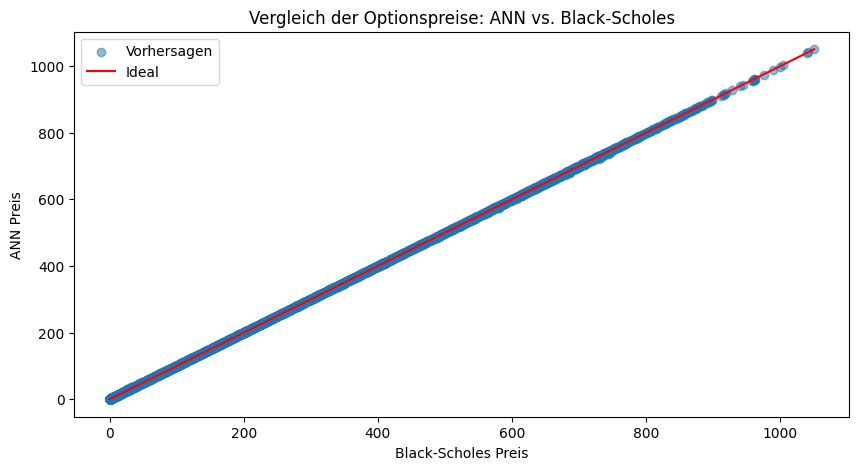

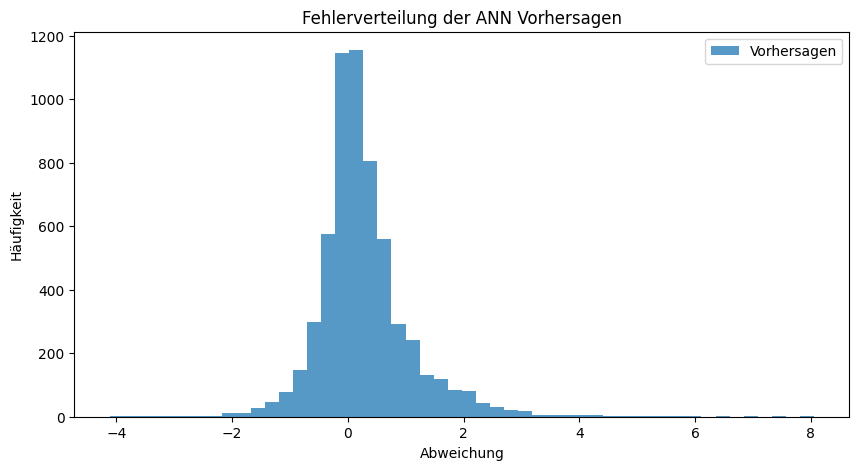

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Plot 1: ANN vs. Black-Scholes
plt.figure(figsize=(10, 5))
plt.scatter(y_test, y_predSklearn, alpha=0.5, label='Vorhersagen')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', label='Ideal')
plt.xlabel('Black-Scholes Preis')
plt.ylabel('ANN Preis')
plt.title('Vergleich der Optionspreise: ANN vs. Black-Scholes')
plt.legend()
plt.show()

# Plot 2: Error Distribution
plt.figure(figsize=(10, 5))
errors = y_test - y_predSklearn
plt.hist(errors, bins=50, alpha=0.75, label='Vorhersagen')
plt.xlabel('Abweichung')
plt.ylabel('Häufigkeit')
plt.title('Fehlerverteilung der ANN Vorhersagen')
plt.legend()
plt.show()

In [ ]:
import plotly.graph_objects as go
import plotly.express as px

# Plot: Error distribution
errors = y_test - y_predKeras

fig2 = px.histogram(
    errors, nbins=300, opacity=1.0,
    labels={'value': 'Abweichung'},
    title='Fehlerverteilung der ANN Vorhersagen' )

fig2.update_layout(
    xaxis_title='<b>Abweichung</b>',
    yaxis_title='<b>Häufigkeit</b>',
    legend_title='Legende' )

In [ ]:
import plotly.graph_objects as go
import plotly.express as px

# Plot 1: ANN vs. Black-Scholes
fig1 = go.Figure()

fig1.add_trace(go.Scatter(
    x=y_test, y=y_predKeras,
    mode='markers',
    name='Vorhersagen',
    opacity=0.9 ))

fig1.add_trace(go.Scatter(
    x=[min(y_test), max(y_test)],
    y=[min(y_test), max(y_test)],
    mode='lines',
    name='Theoretical Option preis',
    line=dict(color='red') ))

fig1.update_layout(
    title='Vergleich der Optionspreise: ANN Model vs. Black-Scholes',
    xaxis_title='<b>Black-Scholes Option Preis</b>',
    yaxis_title='<b>ANN Model Preis</b>',
    legend_title='Legende' )

In [ ]:
import plotly.graph_objects as go
import plotly.express as px

# Plot: Errors
errors1 = y_test - y_predSklearn
errors2 = y_test_new - y_predKeras 

fig = go.Figure()

fig.add_trace(go.Histogram(
    x=errors1,
    nbinsx=300,
    opacity=0.5,
    name='ANN Vorhersagen mit Black-Scholes Preis als Ausgabeparameter',
    marker_color='blue'
))

# Add the second histogram for comparison
fig.add_trace(go.Histogram(
    x=errors2,
    nbinsx=300,
    opacity=0.5,
    name='ANN Vorhersagen mit Sol-3 Preis als Ausgabeparameter',
    marker_color='green'
))

fig.update_layout(
    xaxis_title='<b>Abweichung</b>',
    yaxis_title='<b>Häufigkeit</b>',
    legend_title='Legende',
    barmode='overlay'
)

In [ ]:
import plotly.graph_objects as go
import plotly.express as px

# Plot 1: ANN vs. Black-Scholes
fig1 = go.Figure()

fig1.add_trace(go.Scatter(
    x=y_test, y=y_predSklearn,
    mode='markers',
    name='Vorhersagen mit Sol-3 Preis als Ausgabeparameter',
    opacity=1
))

# Add the second trace for the ANN predictions with Black-Scholes price as output parameter
fig1.add_trace(go.Scatter(
    x=y_test_new, y=y_predKeras,
    mode='markers',
    name='Vorhersagen mit Black-Scholes Preis als Ausgabeparameter',
    opacity=1
))

fig1.add_trace(go.Scatter(
    x=[min(y_test), max(y_test)],
    y=[min(y_test), max(y_test)],
    mode='lines',
    name='Ideal',
    line=dict(color='yellow')
))

fig1.update_layout(
    title='Vergleich der Ausgabeparamter: Black-Scholes vs. Sol-3 Daten',
    xaxis_title='Optimaler Preis',
    yaxis_title='ANN Preis',
    legend_title='Legende'
)

In [25]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig = make_subplots( specs=[[{"secondary_y": True}]] )

#fig.add_trace( go.Scatter( y= history.history['val_loss'], name = "val_loss"),
#              secondary_y = False,)

fig.add_trace( go.Scatter( y= history.history['loss'], name = "loss"),
              secondary_y = False,)

fig.update_layout( title_text = "Loss of ANN Model")

fig.update_xaxes( title_text="Epoch" )
fig.update_yaxes( title_text="Loss" )

Text(0, 0.5, 'Optionspreis')

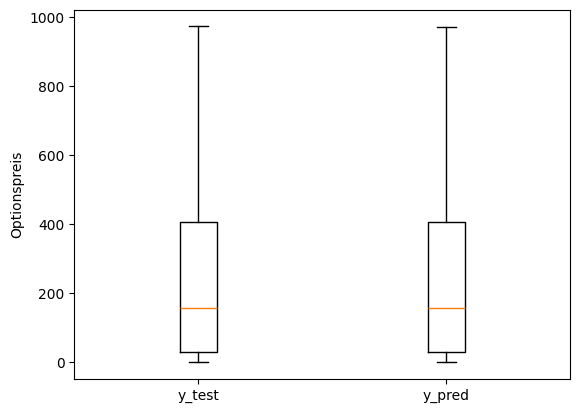

In [ ]:
import matplotlib.pyplot as plt

plt.boxplot((y_test,y_predSklearn), showfliers = False, labels=('y_test', 'y_pred'))
plt.ylabel('Optionspreis')

In [ ]:
import plotly.express as px
import plotly.graph_objects as go

fig = go.Figure()

# Add box plot
fig.add_trace(go.Box(
    x=data['exercisePriceValue'],
    y=data['theoPrice'],
    boxpoints=False,
    marker_color='lightblue',
    name='Box Plot'
))

# Add strip plot
#fig.add_trace(go.Scatter(
#    x=data['exercisePriceValue'],
#    y=data['theoPrice'],
#    mode='markers',
#    marker=dict(color='gray', size=4),
#    name='Strip Plot'
#))

# Update layout
fig.update_layout(
    xaxis=dict(type='log', title='Ausübungspreis', gridcolor='lightgray'),
    yaxis=dict(title='Black-Scholes Preis'),
    showlegend=False,
    template='plotly_white'
)

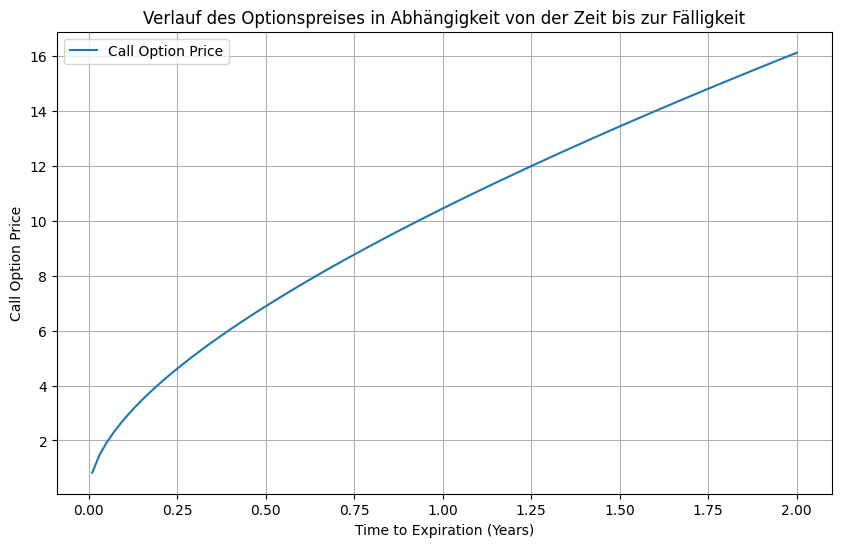

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

# Black-Scholes-Merton formula of european Call-option
def black_scholes_call(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    call_price = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return call_price

# Parameters
S = 100  # actual stock price
K = 100  # strike price
r = 0.05  # interest rate
sigma = 0.2  # volatility

# Time to expiration values from 0.01 to 2 years
T = np.linspace(0.01, 2, 100)

# Calculate the option prices
call_prices = [black_scholes_call(S, K, t, r, sigma) for t in T]

# Data in DataFrame
data = pd.DataFrame({'Time to Expiration': T, 'Call Price': call_prices})

# Plot of the Call Option Price as a function of Time to Expiration
plt.figure(figsize=(10, 6))
plt.plot(data['Time to Expiration'], data['Call Price'], label='Call Option Price')
plt.xlabel('Time to Expiration (Years)')
plt.ylabel('Call Option Price')
plt.title('Verlauf des Optionspreises in Abhängigkeit von der Zeit bis zur Fälligkeit')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
comparison_results_ = {
    'ErrorFunc': ['MSE', 'MAE'],
    'MLPRegressor': [0.834, 1.7123],
    'TensorFlow': [0.8198, 0.7115],
    'XGBoostRegressor': [12.211, 2.3119]
}

# Create a table using Plotly for comparison results
fig8 = go.Figure(data=[go.Table(

    header=dict(values=['<b>Verlustfunktion', '<b>MLPRegressor', '<b>TensorFlow', '<b>XGBoostRegressor'], align='center'),

    cells=dict(values=[
        comparison_results_['ErrorFunc'],
        [f'{x:.4f}' for x in comparison_results_['MLPRegressor']],
        [f'{x:.4f}' for x in comparison_results_['TensorFlow']],
        [f'{x:.4f}' for x in comparison_results_['XGBoostRegressor']]
    ],   

    font = dict(color = 'black', family="Arial", size = 12))
)])

fig8.update_layout( title = '<b>Werte der Verlustfunktionen<b>', width = 800, height = 256)

fig8.show()